# K/π horn and Thermal-FIST freeze-out fits

Analysis behind the paper on the K/π "horn" and the test of **H1**: at HADES (√s<sub>NN</sub> = 2.4 GeV) a
strangeness-canonical ensemble (SCE) describes the data better than a grand-canonical ensemble (GCE).

Run the notebook top to bottom. All logic lives in the `horn_thermal` package (`src/horn_thermal/`); this
notebook calls it and shows the results. Every figure is saved to `figures/`, and the numbers behind each
figure to `results/figure_data/`.

| Section | Output |
|---|---|
| 1. Fig. 1 | the K/π horn |
| 2. Fits | the valid Thermal-FIST fit for each data point |
| 3. Fig. 2 | our STAR fits against STAR's published fits |
| 4. Fig. 3 | freeze-out phase diagram, T versus μ<sub>B</sub> |
| 5. Fig. 4 | the H1 test at HADES |
| 6. Fig. 5 | model versus measured horn (extra check) |

> **Check before publishing.** All yields were transcribed by hand from the published tables; compare them
> with the papers. Sources and feed-down conventions are in `data/SOURCES.md`.

In [1]:
import sys
from pathlib import Path

try:
    import horn_thermal
except ImportError:                      # not installed: use the copy next to this notebook
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import horn_thermal

import matplotlib.pyplot as plt
import pandas as pd

from horn_thermal import config, fits as F, horn as H, plotting as P

pd.set_option("display.width", 200)
print("Reading data from:", config.DATA.relative_to(config.ROOT))

Reading data from: data


## 1. Fig. 1: the K/π horn

K⁺/π⁺ (filled) and K⁻/π⁻ (open) from HADES, STAR fixed target (FXT), NA49, STAR BES and ALICE.
Integrated yields (dN/dy at mid-rapidity; HADES: 4π multiplicities). Where an experiment quotes 0–5 % and
5–10 % separately, the two are averaged to approximate 0–10 %. Ratio errors add the two yield errors in
quadrature and treat them as uncorrelated. The lines are shape-preserving (PCHIP) interpolations,
**a guide to the eye, not a fit or a model**.

The yields, with the source of every row, are in `data/raw/KtoPi_horn_raw_yields.csv`.
`load_raw_yields` stops with an error if any row is listed twice, because averaging duplicates would
shrink the error bars.

,sqrt_sNN_GeV,experiment,system,centrality,Kp_pip,Kp_pip_err,Km_pim,Km_pim_err
0,2.4,HADES,Au+Au,0-10%+0-20%*,0.0064,0.0008,0.0000,0.0000
1,3.2,STAR FXT,Au+Au,0-5%,0.0785,0.0074,0.0040,0.0004
2,3.5,STAR FXT,Au+Au,0-5%,0.0964,0.0117,0.0071,0.0010
3,3.9,STAR FXT,Au+Au,0-5%,0.1318,0.0177,0.0152,0.0025
4,4.5,STAR FXT,Au+Au,0-5%,0.1619,0.0236,0.0220,0.0030
5,6.3,NA49,Pb+Pb,0-7.2%,0.2250,0.0149,0.0658,0.0036
6,7.6,NA49,Pb+Pb,0-7.2%,0.2554,0.0217,0.0808,0.0047
7,7.7,STAR,Au+Au,0-5%+5-10%,0.2239,0.0193,0.0775,0.0066
8,11.5,STAR,Au+Au,0-5%+5-10%,0.2063,0.0208,0.0969,0.0097
9,19.6,STAR,Au+Au,0-5%+5-10%,0.1848,0.0194,0.1145,0.0122


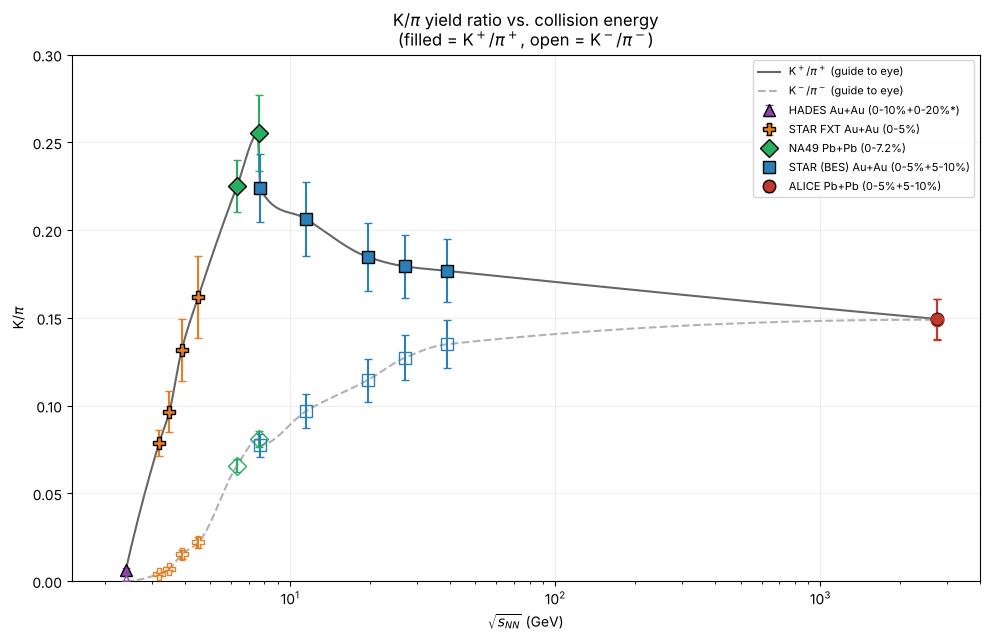

In [2]:
raw = H.load_raw_yields()
horn = H.build_horn(raw)
horn.to_csv(config.RESULTS / "horn_ratios.csv", index=False)
display(horn.round(4))

fig = P.plot_horn(horn)
P.save(fig, "fig1_horn.png")
plt.show()

## 2. Thermal-FIST fits: read and select the valid ones

Every `fit_*.txt` in `data/thermal_fist/outputs/` is parsed and one valid fit is chosen per data point from the
**contents** of the files (not their names), so superseded or failed runs are skipped automatically:

* **STAR BES, NA49, ALICE:** ideal HRG, μ<sub>B</sub> and γ<sub>S</sub> free.
* **HADES, FXT:** μ<sub>B</sub> fixed to 790, 698, 669, 634 and 587 MeV (Cleymans curve), T not on a fit limit.
* **HADES strangeness-canonical:** R<sub>c</sub> free and below the 30 fm limit; lowest χ² if several remain.
* If several valid files remain, the latest one is used. A warning is printed if nothing valid is found.

In [3]:
fits_all = F.read_all_fits()
print(len(fits_all), "Thermal-FIST output files found")

fits = F.select_fits(fits_all)
fits.to_csv(config.RESULTS / "thermal_fit_results_selected.csv", index=False)

cols = ["experiment", "variant", "ensemble", "sqrt_sNN_GeV", "T", "T_err", "muB", "muB_err", "muB_fixed",
        "gammaS", "gammaS_err", "Rc", "chi2", "ndf", "p_value", "file"]
display(fits[cols].round(3))

16 Thermal-FIST output files found


,experiment,variant,ensemble,sqrt_sNN_GeV,T,T_err,muB,muB_err,muB_fixed,gammaS,gammaS_err,Rc,chi2,ndf,p_value,file
0,HADES,standard,grand-canonical,2.4,36.529,0.572,790.000,NaN,True,1.000,NaN,NaN,12.302,2,0.002,fit_HADES_2p4GeV_grandcanonical_muB790fixed.txt
1,HADES,standard,strangeness-canonical,2.4,42.961,1.948,790.000,NaN,True,1.000,NaN,20.974,3.240,1,0.072,fit_HADES_2p4GeV_strangenesscanonical_muB790fi...
2,STAR FXT,standard,grand-canonical,3.2,65.954,1.518,698.000,NaN,True,1.000,NaN,NaN,2.763,2,0.251,fit_FXT_3p2GeV_grandcanonical_muB698fixed.txt
3,STAR FXT,standard,grand-canonical,3.5,71.987,2.450,669.000,NaN,True,1.000,NaN,NaN,0.672,2,0.715,fit_FXT_3p5GeV_grandcanonical_muB669fixed.txt
4,STAR FXT,standard,grand-canonical,3.9,82.219,3.821,634.000,NaN,True,1.000,NaN,NaN,0.867,2,0.648,fit_FXT_3p9GeV_grandcanonical_muB634fixed.txt
5,STAR FXT,standard,grand-canonical,4.5,93.300,5.598,587.000,NaN,True,1.000,NaN,NaN,0.660,2,0.719,fit_FXT_4p5GeV_grandcanonical_muB587fixed.txt
6,NA49,standard,grand-canonical,6.3,128.966,3.036,443.932,10.390,False,0.949,0.067,NaN,0.202,2,0.904,fit_NA49_20A_muB_gammaS_free.txt
7,NA49,p inclusive,grand-canonical,6.3,120.832,2.096,449.654,9.864,False,1.008,0.075,NaN,0.867,2,0.648,fit_NA49_20A_protons_inclusive_muB_gammaS_free...
8,NA49,standard,grand-canonical,7.6,140.166,4.751,412.326,17.517,False,1.022,0.093,NaN,0.746,2,0.689,fit_NA49_30A_muB_gammaS_free.txt
9,NA49,p inclusive,grand-canonical,7.6,128.622,2.474,416.752,15.572,False,1.062,0.094,NaN,2.357,2,0.308,fit_NA49_30A_protons_inclusive_muB_gammaS_free...


## 3. Fig. 2: benchmark against the published STAR fits

STAR BES, 0–5 % central, ratios π⁻/π⁺, K⁻/K⁺, p̄/p, K⁻/π⁻, p̄/π⁻ (STAR Table VI), grand-canonical ideal HRG with
T, μ<sub>B</sub> and γ<sub>S</sub> free, μ<sub>Q</sub> from Q/B = 0.4 and zero net strangeness. Red squares are STAR's
published ratio fit (Table VIII of arXiv:1701.07065), which also included Λ and Ξ and used μ<sub>Q</sub> = 0.

,sqrt_sNN_GeV,T,T_pub,T_pull,muB,muB_pub,muB_pull,gammaS,gammaS_pub,gammaS_pull,chi2_ndf
0,7.7,141.70,144.3,-0.60,401.92,398.2,0.15,0.93,0.95,-0.16,0.28
1,11.5,149.70,149.4,0.05,289.63,287.3,0.08,0.80,0.92,-0.85,0.44
2,19.6,150.82,153.9,-0.43,179.64,187.9,-0.35,0.75,0.96,-1.58,0.46
3,27.0,150.35,155.0,-0.65,139.64,144.4,-0.24,0.80,0.98,-1.40,0.14
4,39.0,150.97,156.4,-0.73,96.22,103.2,-0.40,0.79,0.94,-1.18,0.19


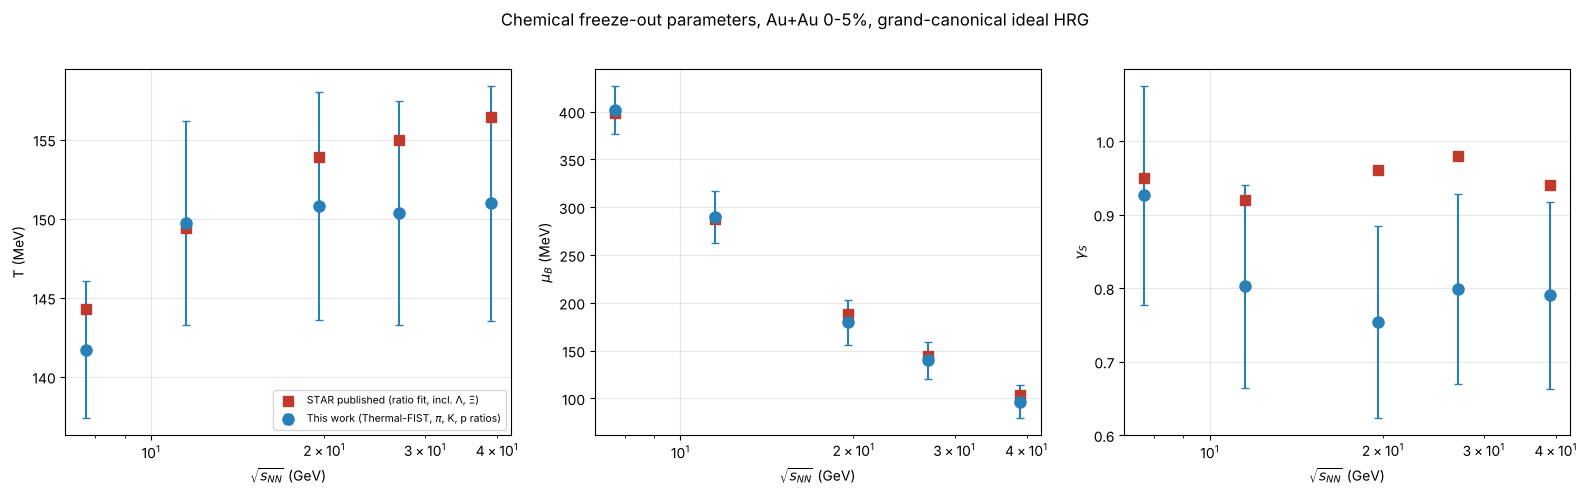

In [4]:
bench = F.benchmark_vs_star(fits)
display(bench[["sqrt_sNN_GeV", "T", "T_pub", "T_pull", "muB", "muB_pub", "muB_pull",
               "gammaS", "gammaS_pub", "gammaS_pull", "chi2_ndf"]].round(2))

fig = P.plot_benchmark(bench)
P.save(fig, "fig2_benchmark_vs_STAR.png")
plt.show()

## 4. Fig. 3: phase diagram, T versus μ<sub>B</sub>

Points with horizontal error bars have μ<sub>B</sub> fitted (STAR, NA49, ALICE). **HADES and FXT have μ<sub>B</sub>
fixed to the Cleymans et al. parametrization, so they have no μ<sub>B</sub> error bar** and their T depends on that
assumption. Open triangles: HADES strangeness-canonical fit (R<sub>c</sub> free). Grey line: Cleymans et al.,
Phys. Rev. C 73, 034905. Dashed: Andronic-type parametrization (T<sub>lim</sub> = 158.4 MeV,
μ<sub>B</sub> = 1307.5 MeV / (1 + 0.288 √s)); **confirm its citation before using the curve in a paper.**

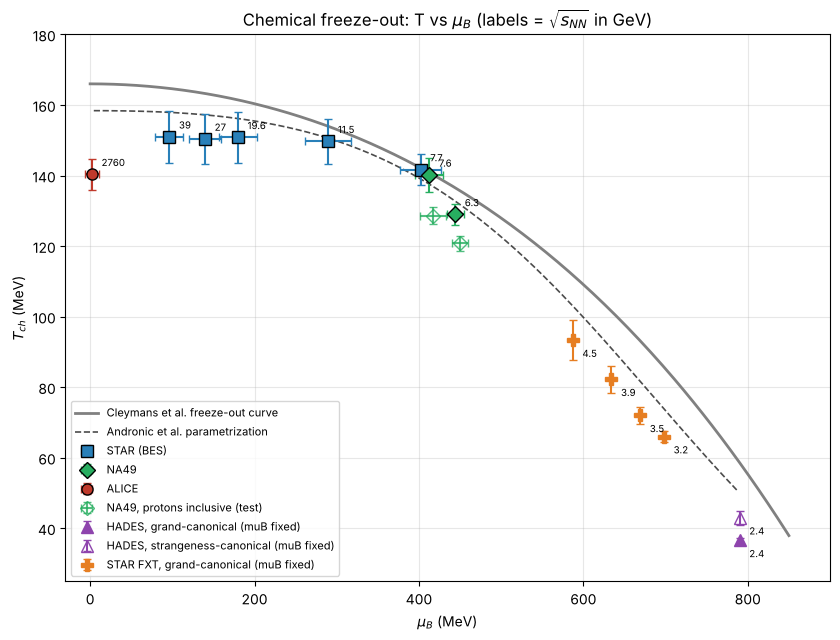

,experiment,ensemble,sqrt_sNN_GeV,muB,T,T_err,T_curve,dT,Rc,chi2,ndf,p_value
0,HADES,grand-canonical,2.4,790.0,36.529,0.572,58.530,-22.001,NaN,12.302,2,0.002
1,HADES,strangeness-canonical,2.4,790.0,42.961,1.948,58.530,-15.568,20.974,3.240,1,0.072
2,STAR FXT,grand-canonical,3.2,698.0,65.954,1.518,85.666,-19.712,NaN,2.763,2,0.251
3,STAR FXT,grand-canonical,3.5,669.0,71.987,2.450,93.202,-21.215,NaN,0.672,2,0.715
4,STAR FXT,grand-canonical,3.9,634.0,82.219,3.821,101.679,-19.460,NaN,0.867,2,0.648
5,STAR FXT,grand-canonical,4.5,587.0,93.300,5.598,111.824,-18.524,NaN,0.660,2,0.719


In [5]:
fig = P.plot_phase_diagram(fits)
P.save(fig, "fig3_phase_diagram.png")
plt.show()

# Offset of the low-energy fits from the literature curve (quoted in the text)
low = F.low_energy_offsets(fits)
display(low[["experiment", "ensemble", "sqrt_sNN_GeV", "muB", "T", "T_err", "T_curve", "dT",
             "Rc", "chi2", "ndf", "p_value"]].round(3))

## 5. Fig. 4: the H1 test, HADES ratios under two ensembles

Au+Au, √s<sub>NN</sub> = 2.4 GeV, μ<sub>B</sub> fixed to 790 MeV. Three measured ratios (black) against the best-fit
predictions of the **grand-canonical** model (one free parameter, T) and the **strangeness-canonical** model
(two free parameters, T and R<sub>c</sub>). The right panel shows each miss in units of the measurement
uncertainty, (model − data)/error; χ² is the sum of their squares.

K⁻/K⁺ is the ratio the grand-canonical model cannot reproduce. Keep in mind: only 3 data points; the SCE fit
has 1 degree of freedom; R<sub>c</sub> ≈ 21 fm is larger than the nucleus; π⁻/π⁺ accounts for almost all of the
remaining χ².

,data,data_err,gce_model,gce_pull,sce_model,sce_pull
ratio,,,,,,
pi-/pi+,1.83900,0.17000,2.09183,1.48723,2.14328,1.78989
K+/pi+,0.00643,0.00083,0.00700,0.68575,0.00643,-0.00090
K-/K+,0.00717,0.00110,0.00376,-3.10164,0.00696,-0.19070


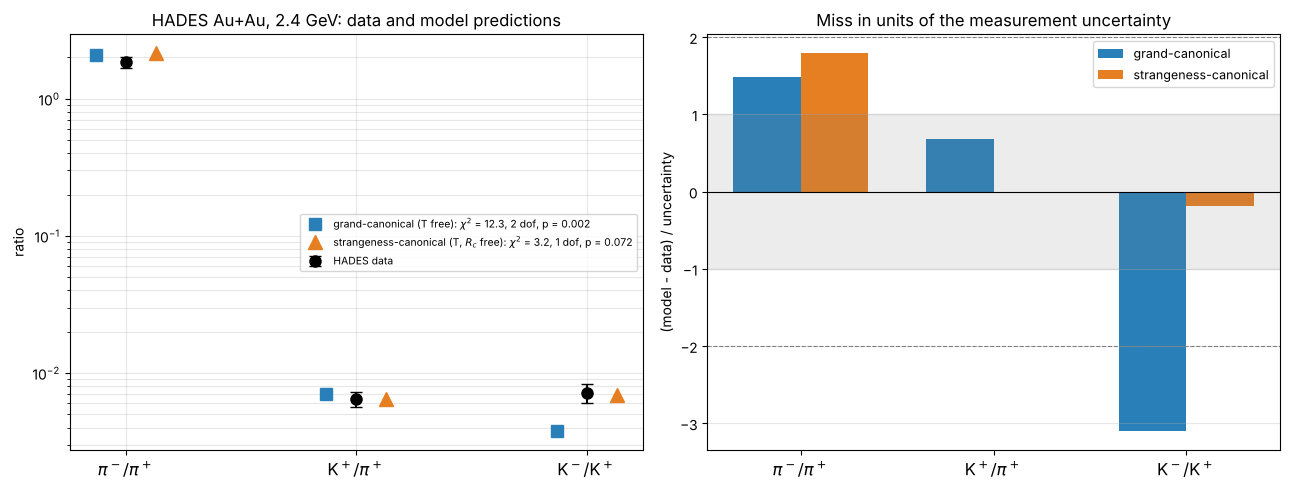

grand-canonical:       chi2 = 12.30 (2 dof), p = 0.0021, T = 36.5 MeV
strangeness-canonical: chi2 = 3.24 (1 dof), p = 0.0719, T = 43.0 MeV, Rc = 21.0 fm
improvement:           delta chi2 = 9.06 for 1 extra parameter, p = 0.0026


In [6]:
gce, sce, h1 = F.h1_comparison(fits)
display(h1.round(5))

fig = P.plot_h1(gce, sce, h1)
P.save(fig, "fig4_HADES_ensemble_comparison.png")
plt.show()

print(P.h1_summary(gce, sce))

## 6. Fig. 5 (extra): does the fitted model reproduce the horn?

Model K⁺/π⁺ and K⁻/π⁻ at the fitted parameters of each energy, against the measured horn. Where a ratio was not
fitted directly, it is derived from the fitted ones (`fits.model_horn`). Because each energy was fitted
separately to these same ratios, this shows that the fits **describe** the horn. It does not show that the model
**predicts** it. An independent test would run Thermal-FIST along the smooth Cleymans curve (T, μ<sub>B</sub>) with
γ<sub>S</sub> = 1 and compare with the data.

,label,sqrt_sNN_GeV,Kp_pip_model,Kp_pip,Kp_pip_pull,Km_pim_model,Km_pim,Km_pim_pull
0,HADES grand-canonical,2.4,0.00700,0.00643,0.68643,0.00001,0.00002,-2.65195
1,HADES strangeness-canonical,2.4,0.00643,0.00643,-0.00102,0.00002,0.00002,0.46097
2,STAR FXT grand-canonical,3.2,0.07998,0.07846,0.20511,0.00326,0.00400,-1.73032
3,STAR FXT grand-canonical,3.5,0.09641,0.09639,0.00212,0.00607,0.00707,-1.04714
4,STAR FXT grand-canonical,3.9,0.13092,0.13182,-0.05094,0.01241,0.01518,-1.09536
5,STAR FXT grand-canonical,4.5,0.16257,0.16192,0.02715,0.02322,0.02204,0.39224
6,NA49 grand-canonical,6.3,0.21914,0.22497,-0.39070,0.06582,0.06580,0.00553
7,NA49 grand-canonical,7.6,0.24371,0.25542,-0.53982,0.08095,0.08083,0.02603
8,STAR grand-canonical,7.7,0.22257,0.22385,-0.06641,0.07694,0.07752,-0.08719
9,STAR grand-canonical,11.5,0.18931,0.20633,-0.81680,0.09477,0.09694,-0.22491


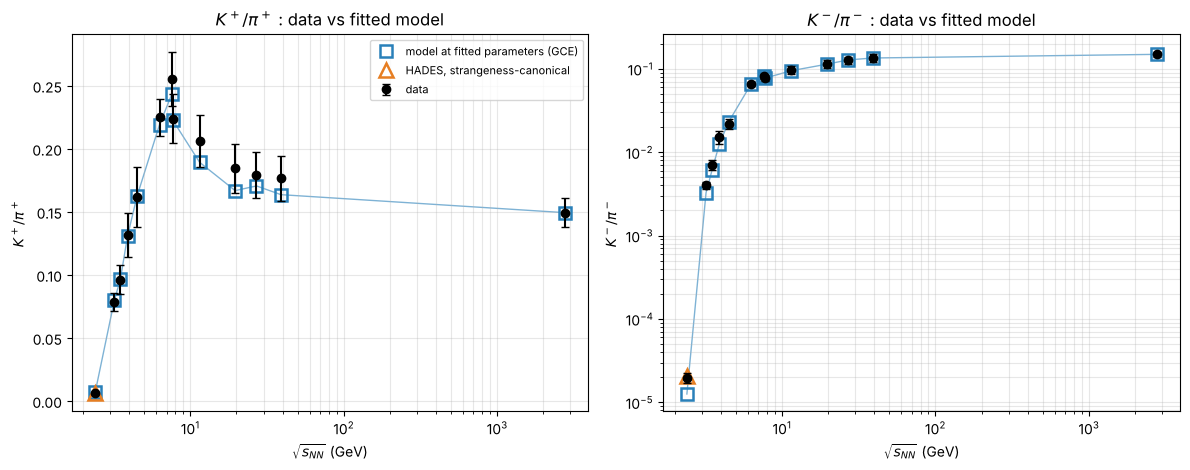

In [7]:
check = F.model_horn(fits, horn)
display(check[["label", "sqrt_sNN_GeV", "Kp_pip_model", "Kp_pip", "Kp_pip_pull",
               "Km_pim_model", "Km_pim", "Km_pim_pull"]].round(5))

fig = P.plot_horn_model_check(check)
P.save(fig, "fig5_horn_model_check.png")
plt.show()

## Data sources, feed-down and software

See [`data/SOURCES.md`](../data/SOURCES.md) for every reference, the feed-down convention of each dataset, the
Thermal-FIST settings, and the known limitations. Software: Thermal-FIST 1.6.1 with the PDG2025 list
(Vovchenko and Stoecker, Comput. Phys. Commun. 244, 295 (2019), arXiv:1901.05249).